# Setup

## Load packages

In [1]:
# Load up necessary packages. 
import os
import glob
import importlib
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter1d
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Import my custom utils.
from pathlib import Path
import importlib.util

UTILS_PATH = Path.cwd() / "utils.py"
if not UTILS_PATH.is_file():
    UTILS_PATH = Path.cwd() / "optimized_pipeline" / "utils.py"
spec = importlib.util.spec_from_file_location("optimized_example_utils", UTILS_PATH)
utils = importlib.util.module_from_spec(spec)
spec.loader.exec_module(utils)
if not hasattr(utils, "_LagScoringContext"):
    raise RuntimeError("Set UTILS_PATH to optimized_pipeline/utils.py.")
print(f"Using {UTILS_PATH.resolve()}")

Using /tscc/projects/ps-yeolab3/kflanagan/plip_plop/matrix_speed_up_test/optimized_pipeline/utils.py


# Load results

In [2]:
INPUT_DIR = "/tscc/lustre/ddn/scratch/kflanagan/plip_plop_results/processed_inputs/"

comparison_table = pd.read_csv("/tscc/nfs/home/kflanagan/projects/plip_plop/matrix_correspondance/select_comparisons/encode_initial_30_comparisons.tsv", sep="\t")


In [3]:
# Windows currently in our test zoo.
example_windows = pd.DataFrame([
    # Easy agreement.
    ["easy_agreement", "PUM1",  "PUM2",   "chrY",  10200042,  10200342],
    ["easy_agreement", "PUM1",  "PUM2",   "chr12", 93395361,  93395661],
    ["easy_agreement", "FUS",   "TAF15",  "chr3",  146121064, 146121364],
    ["easy_agreement", "FUS",   "TAF15",  "chr14", 52646268,  52646568],

    # No agreement.
    ["no_agreement", "QKI",   "NOLC1", "chr7", 128092393, 128092693],
    ["no_agreement", "SND1",  "GRWD1", "chr2", 196720471, 196720771],
    ["no_agreement", "ILF3",  "NCBP2",  "chr4", 39527182,  39527482],

    # Pure displacement.
    ["pure_displacement", "PRPF4", "PRPF8",  "chr10", 99794312,  99794612],
    ["pure_displacement", "PRPF4", "PRPF8",  "chr16", 18815074,  18815374],
    ["pure_displacement", "CPSF6", "CSTF2T", "chr4",  173331527, 173331827],
    ["pure_displacement", "PRPF4", "PRPF8",  "chr18", 693781,     694081],
    ["pure_displacement", "FUS",   "TAF15",  "chr20", 49284292,  49284592],

    # Cross-correlation "shuffled off screen" examples.
    ["shuffled_off_screen", "PUM1", "PUM2",  "chr11", 9589488,  9589788],
    ["shuffled_off_screen", "FUS",  "TAF15", "chr6",  31670881, 31671181],
    ["shuffled_off_screen", "QKI",  "NOLC1", "chr18", 77993533, 77993833],

    # Noisy / low-confidence windows.
    ["noisy", "PRPF4", "PRPF8",  "chr12", 318089,   318389],
    ["noisy", "CPSF6", "CSTF2T", "chr16", 50273059, 50273359],
    ["noisy", "SND1",  "GRWD1",  "chr19", 798540,   798840],

], columns=[
    "zoo_category",
    "rbp_A",
    "rbp_B",
    "chrom",
    "start",
    "end"
])

In [4]:
# Keep only comparisons represented in the current zoo.
wanted_pairs = set(
    zip(
        example_windows["rbp_A"],
        example_windows["rbp_B"]
    )
)

available_pairs = set(
    (
        row["experiment_A"].split("_")[0],
        row["experiment_B"].split("_")[0]
    )
    for _, row in comparison_table.iterrows()
)

missing_pairs = wanted_pairs - available_pairs

if missing_pairs:
    print("\n" + "!" * 70)
    print("WARNING: REQUESTED ZOO COMPARISONS NOT FOUND")
    print("!" * 70)

    for rbp_A, rbp_B in sorted(missing_pairs):
        print(f"  {rbp_A} vs {rbp_B}")

    print("!" * 70 + "\n")

comparison_table = comparison_table[
    comparison_table.apply(
        lambda row: (
            row["experiment_A"].split("_")[0],
            row["experiment_B"].split("_")[0]
        ) in wanted_pairs,
        axis=1
    )
].copy()

In [5]:
comparison_data = {}
all_metadata = []

for comparison_id, row in comparison_table.iterrows():
    experiment_A = row["experiment_A"]
    experiment_B = row["experiment_B"]

    rbp_A = experiment_A.split("_")[0]
    rbp_B = experiment_B.split("_")[0]

    wanted = example_windows[
        (example_windows["rbp_A"] == rbp_A) &
        (example_windows["rbp_B"] == rbp_B)
    ]

    if wanted.empty:
        continue

    npz_file = os.path.join(INPUT_DIR, f"{experiment_A}_{experiment_B}.npz")

    if not os.path.exists(npz_file):
        print(f"Missing: {npz_file}")
        continue

    with np.load(npz_file) as data:

        # Find only the requested windows for this comparison.
        keep = np.zeros(len(data["chrom"]), dtype=bool)
        
        for _, example in wanted.iterrows():
            exact_match = (
                (data["chrom"] == example["chrom"]) &
                (data["start"] == example["start"]) &
                (data["end"] == example["end"])
            )
        
            if exact_match.any():
                keep |= exact_match
                continue
        
            # Exact window was not found.
            print("\n" + "!" * 80)
            print("WARNING: REQUESTED WINDOW NOT FOUND")
            print("!" * 80)
            print(
                f'{rbp_A} vs {rbp_B}: '
                f'{example["chrom"]}:{example["start"]}-{example["end"]}'
            )
        
            # Look for nearby windows on the same chromosome.
            same_chrom = data["chrom"] == example["chrom"]
            nearby_idx = np.where(same_chrom)[0]
        
            if len(nearby_idx) == 0:
                print(f'No windows found at all on {example["chrom"]}.')
                print("!" * 80 + "\n")
                continue
        
            nearby_starts = data["start"][nearby_idx].astype(int)
            nearby_ends = data["end"][nearby_idx].astype(int)
        
            # Coordinate distance from requested window.
            distance = (
                np.abs(nearby_starts - int(example["start"])) +
                np.abs(nearby_ends - int(example["end"]))
            )
        
            order = np.argsort(distance)
        
            print("\nClosest windows on the same chromosome:")
        
            for rank in order[:5]:
                i = nearby_idx[rank]
        
                start_diff = int(data["start"][i]) - int(example["start"])
                end_diff = int(data["end"][i]) - int(example["end"])
        
                print(
                    f'  {data["chrom"][i]}:{data["start"][i]}-{data["end"][i]}'
                    f'   '
                    f'(start {start_diff:+d}, end {end_diff:+d})'
                )
        
            print("!" * 80 + "\n")
        
        idx = np.where(keep)[0]

        print(
            f"{rbp_A} vs {rbp_B}: "
            f"found {len(idx)} / {len(wanted)} requested windows"
        )

        # Load only those windows.
        ip_A = data["ip_signals_A"][idx].astype(np.float32)
        in_A = data["in_signals_A"][idx].astype(np.float32)
        ip_B = data["ip_signals_B"][idx].astype(np.float32)
        in_B = data["in_signals_B"][idx].astype(np.float32)

        ip_A_library_sizes = data["ip_A_library_sizes"]
        in_A_library_sizes = data["in_A_library_sizes"]
        ip_B_library_sizes = data["ip_B_library_sizes"]
        in_B_library_sizes = data["in_B_library_sizes"]

        n_windows = len(ip_A)

        if not (len(ip_A) == len(in_A) == len(ip_B) == len(in_B)):
            raise ValueError(
                f"Signal arrays do not match for comparison {comparison_id}."
            )

        if in_A.shape[1] != 1 or in_B.shape[1] != 1:
            raise ValueError(
                f"Expected one IN replicate for comparison {comparison_id}."
            )

        if any(array.ndim != 3 or array.shape[2] != 300 for array in (ip_A, in_A, ip_B, in_B)):
            raise ValueError("Expected prepared 300-nt signals without context.")

        # Convert raw coverage to RPM.
        ip_A_rpm = ip_A * (1e6 / ip_A_library_sizes[None, :, None])
        in_A_rpm = in_A * (1e6 / in_A_library_sizes[None, :, None])
        ip_B_rpm = ip_B * (1e6 / ip_B_library_sizes[None, :, None])
        in_B_rpm = in_B * (1e6 / in_B_library_sizes[None, :, None])

        # RPM corresponding approximately to one read.
        ip_A_pc = utils.calculate_rpm_pseudocount(ip_A_library_sizes)
        in_A_pc = utils.calculate_rpm_pseudocount(in_A_library_sizes)
        ip_B_pc = utils.calculate_rpm_pseudocount(ip_B_library_sizes)
        in_B_pc = utils.calculate_rpm_pseudocount(in_B_library_sizes)

        # Use the full 300-nt windows for the shared abundance reference.
        signal_A = np.empty_like(ip_A_rpm)
        signal_B = np.empty_like(ip_B_rpm)

        for w in range(n_windows):
            mean_A = ip_A_rpm[w].mean()
            mean_B = ip_B_rpm[w].mean()
            mean_AB = (mean_A + mean_B) / 2

            for r in range(ip_A.shape[1]):
                signal_A[w, r] = utils.abundance_weighted_enrichment(ip_A_rpm[w, r], in_A_rpm[w, 0], ip_A_pc,
                                                                     in_A_pc, mean_AB, smoothing_sigma = 2)

            for r in range(ip_B.shape[1]):
                signal_B[w, r] = utils.abundance_weighted_enrichment(ip_B_rpm[w, r], in_B_rpm[w, 0], ip_B_pc,
                                                                     in_B_pc, mean_AB, smoothing_sigma = 2)

        comparison_data[comparison_id] = {
            "signal_A": signal_A,
            "signal_B": signal_B,
            "ip_A_rpm": ip_A_rpm,
            "in_A_rpm": in_A_rpm,
            "ip_B_rpm": ip_B_rpm,
            "in_B_rpm": in_B_rpm
        }

        metadata = pd.DataFrame({
            "comparison_id": comparison_id,
            "window_idx": np.arange(n_windows),
            "original_window_idx": idx,
            "category": row["category"],
            "experiment_A": experiment_A,
            "experiment_B": experiment_B,
            "chrom": data["chrom"][idx],
            "start": data["start"][idx],
            "end": data["end"][idx],
            "strand": data["strand"][idx],
            "region_id": data["region_id"][idx],
            "block_number": data["block_number"][idx]
        })

        all_metadata.append(metadata)


metadata = pd.concat(all_metadata, ignore_index=True)

metadata = metadata.merge(example_windows[["zoo_category", "chrom", "start", "end"]], on=["chrom", "start", "end"], how="left")

print("Comparisons loaded:", len(comparison_data))
print("Total windows:", len(metadata))

FUS vs TAF15: found 4 / 4 requested windows
PUM1 vs PUM2: found 3 / 3 requested windows
CPSF6 vs CSTF2T: found 2 / 2 requested windows
PRPF4 vs PRPF8: found 4 / 4 requested windows
ILF3 vs NCBP2: found 1 / 1 requested windows
SND1 vs GRWD1: found 2 / 2 requested windows
QKI vs NOLC1: found 2 / 2 requested windows
Comparisons loaded: 7
Total windows: 18


# Make heatmaps

## Helpers

In [6]:
def plot_category(category, island_parameters):

    subset = metadata[metadata["zoo_category"] == category]

    results = []

    for _, row in subset.iterrows():

        comp = comparison_data[row["comparison_id"]]
        window_idx = row["window_idx"]

        signal_A = comp["signal_A"][window_idx].mean(axis=0)
        signal_B = comp["signal_B"][window_idx].mean(axis=0)

        title = (
            f'{row["experiment_A"]} vs '
            f'{row["experiment_B"]}\n'
            f'{row["chrom"]}:'
            f'{row["start"]}-'
            f'{row["end"]}'
        )

        result = utils.identify_islands(signal_A, signal_B, title=title, **island_parameters)
        results.append(result)

    return results

In [7]:
island_parameters = dict(
    seed_threshold_fraction=0.4, growth_threshold_fraction=0.2,
    max_weak_distance=5, gap_tolerance=2, shape_balance_power=1.05,
    ridge_fraction=0.6,
    split_prominence_fraction=0.15, split_min_peak_fraction=0.5,
    split_min_peak_distance=8, split_min_seed_area=5,
    displacement_fold_threshold=2.0,
    mode_score_fraction=0.33
)

## Easy agreement

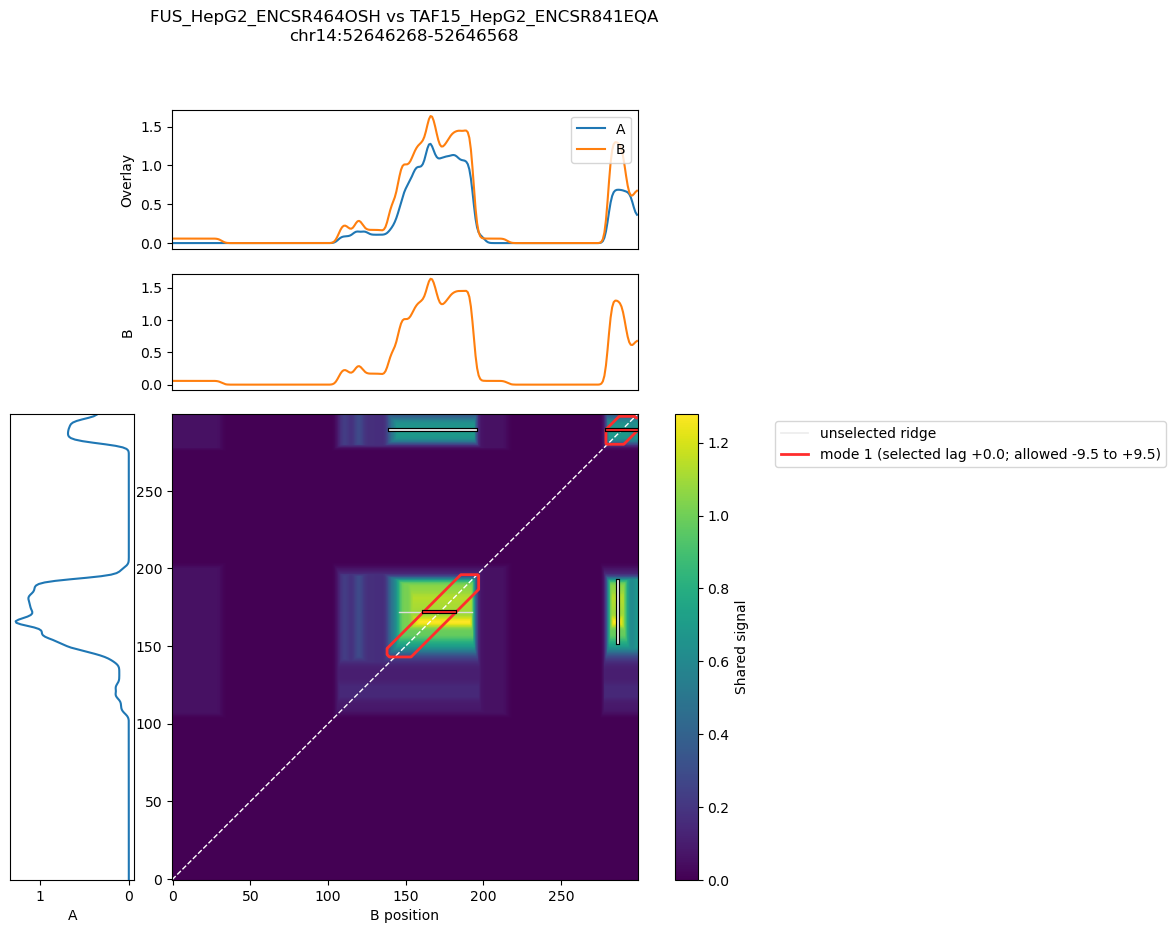

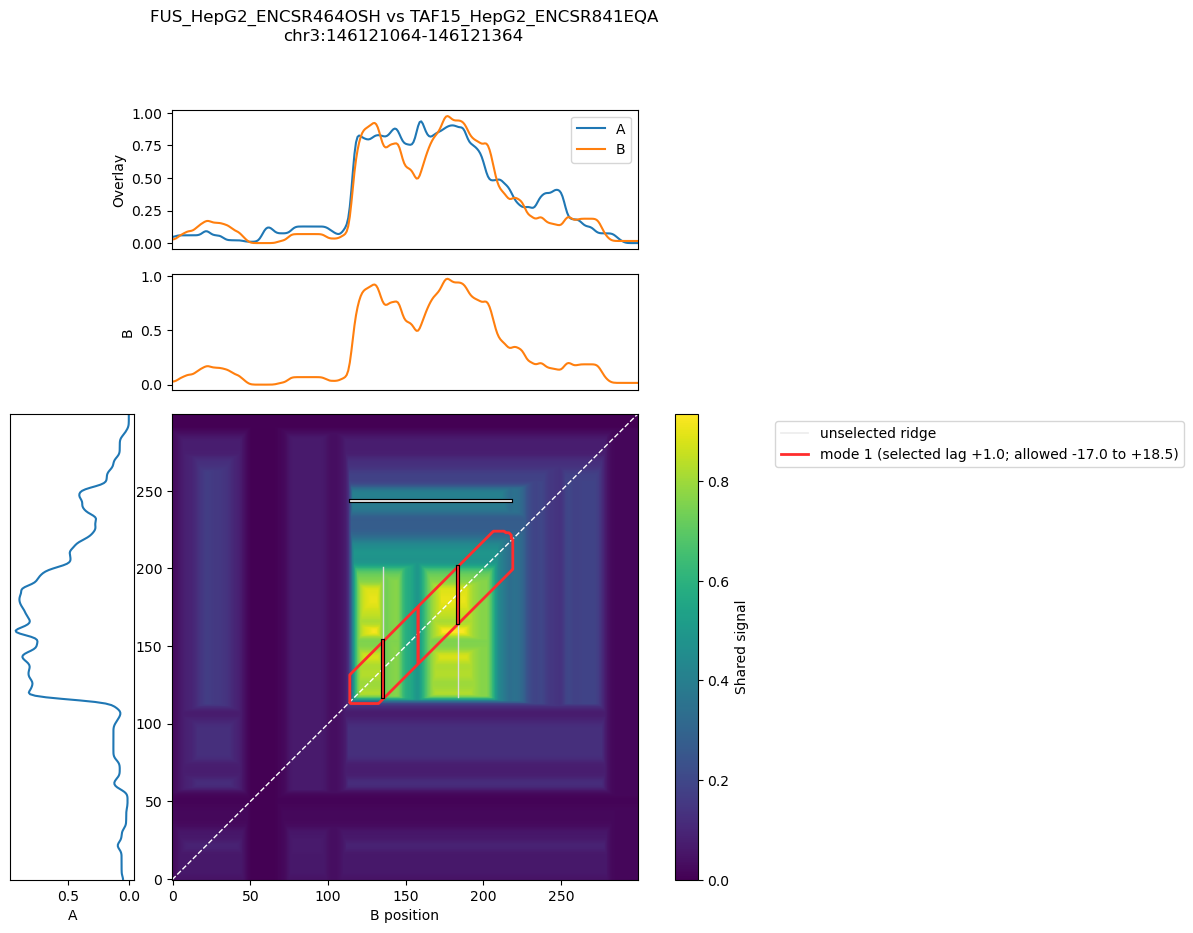

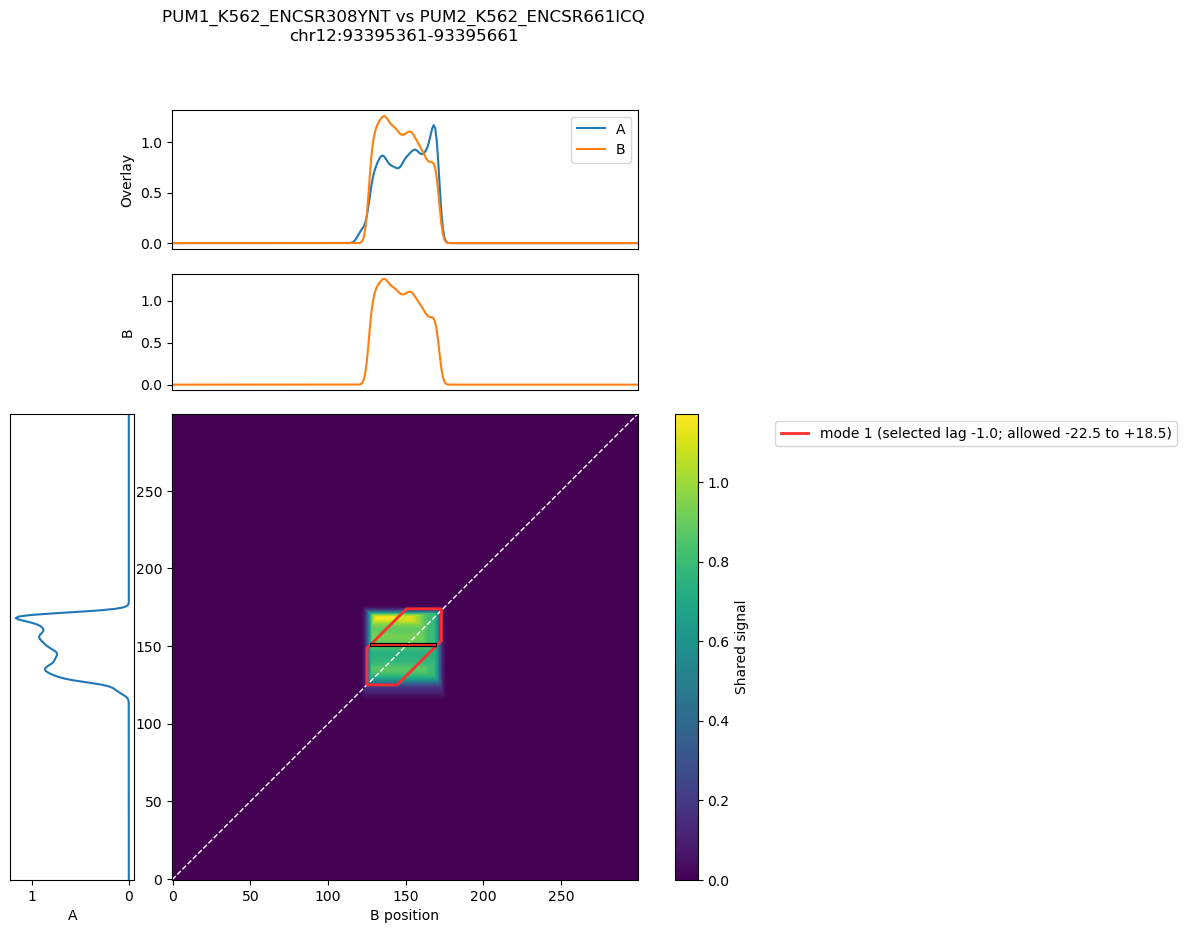

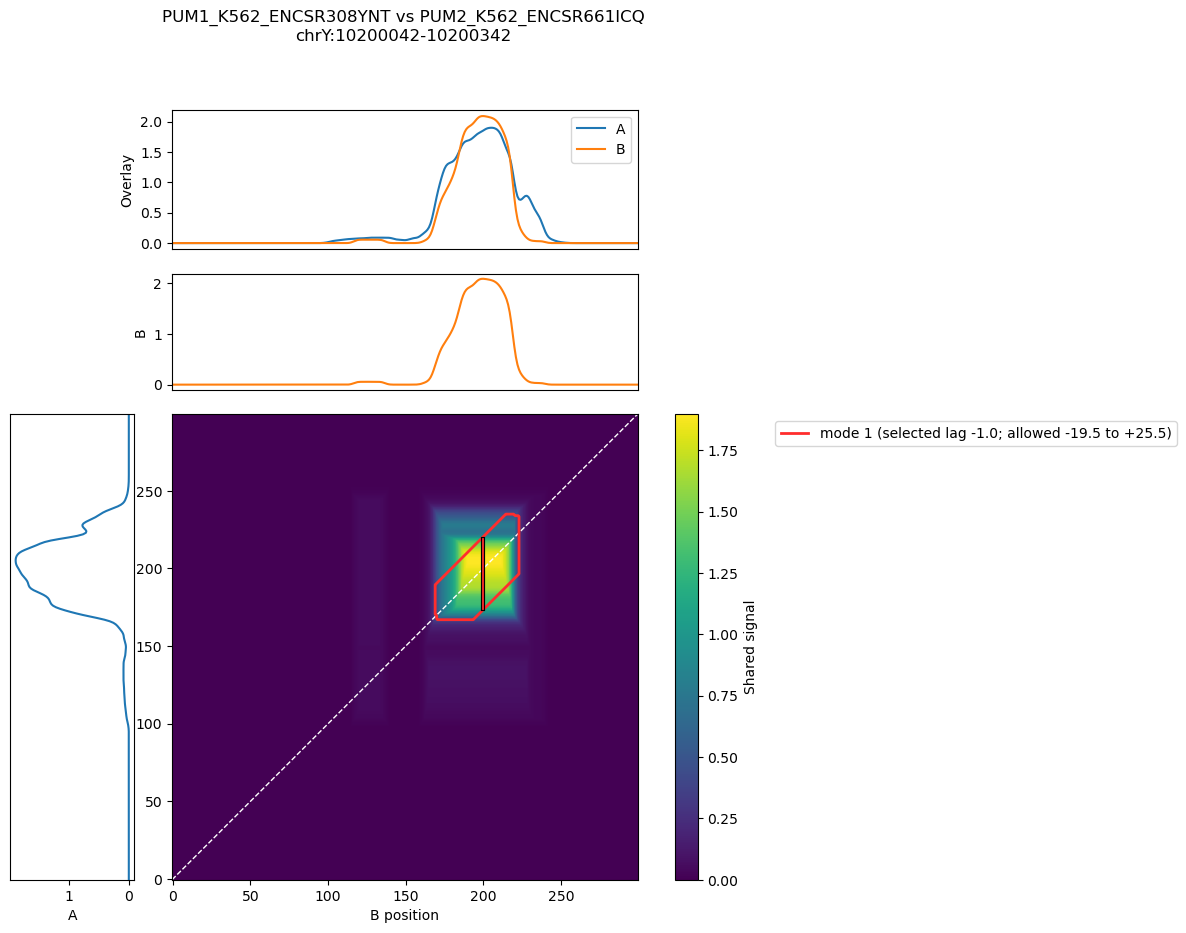

In [8]:
easy_agreement = plot_category("easy_agreement", island_parameters)

In [9]:
Path("pickles").mkdir(exist_ok=True)

with open(f"pickles/real_easy_agreement_horizontal.pkl", "wb") as f:
    pickle.dump(easy_agreement[0], f, protocol=pickle.HIGHEST_PROTOCOL)

with open(f"pickles/real_easy_agreement_gap.pkl", "wb") as f:
    pickle.dump(easy_agreement[3], f, protocol=pickle.HIGHEST_PROTOCOL)

## No agreement

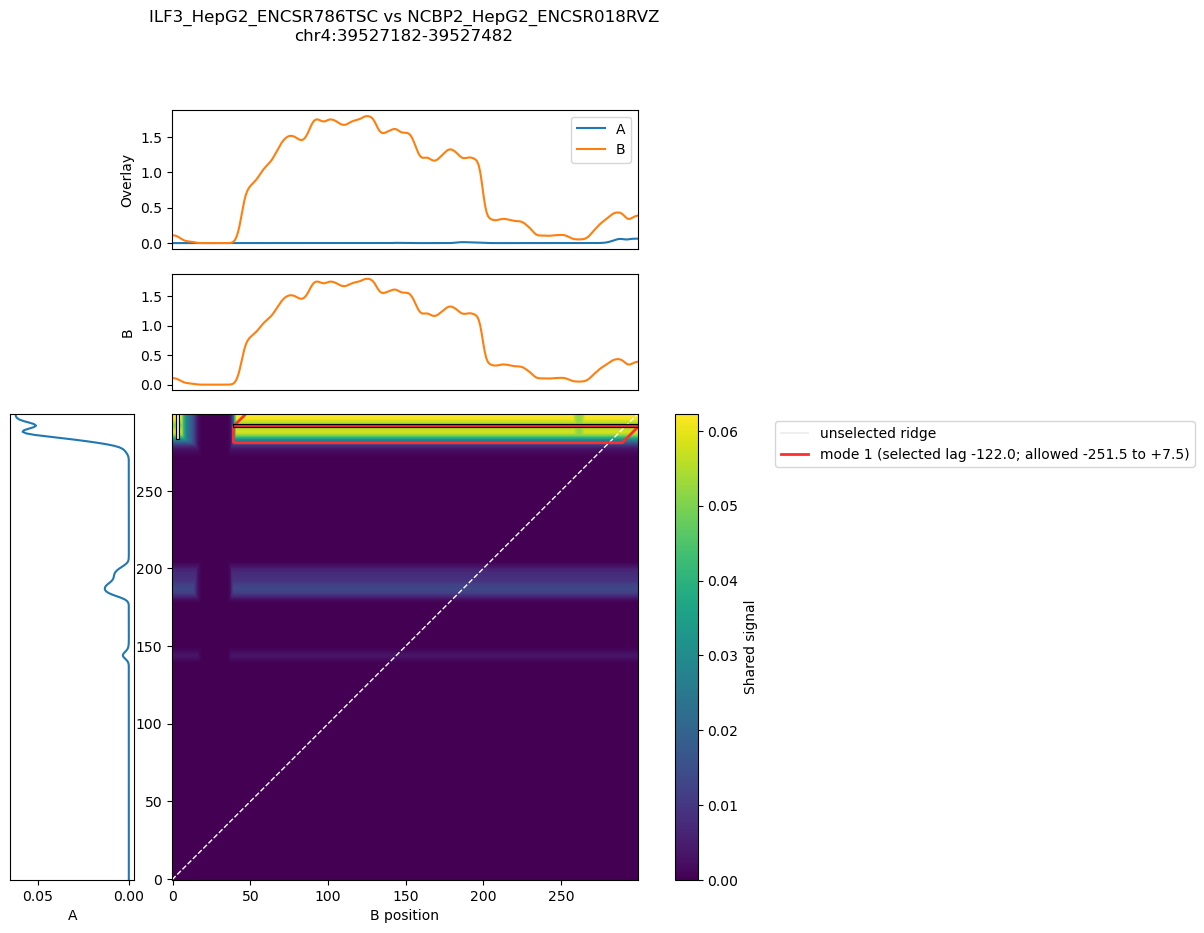

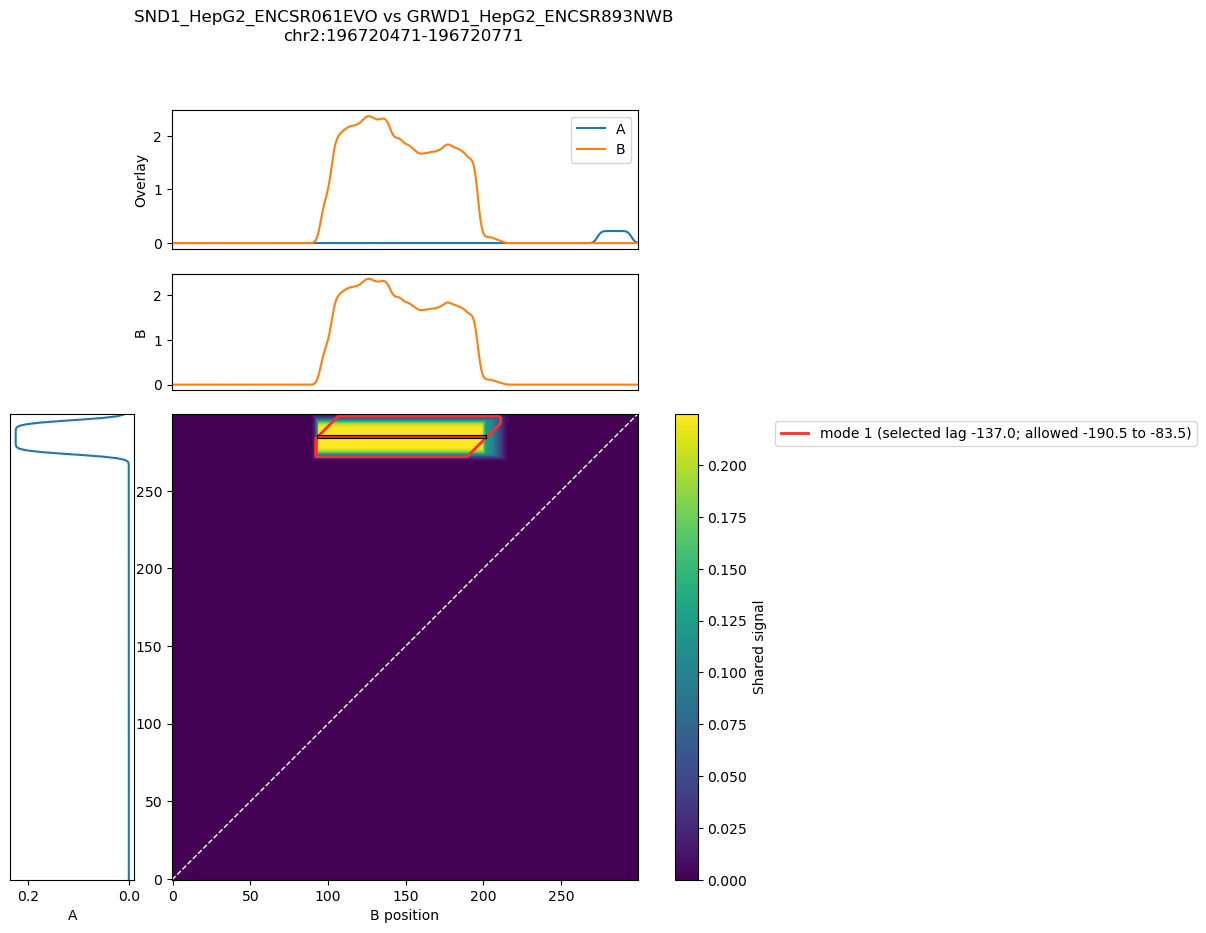

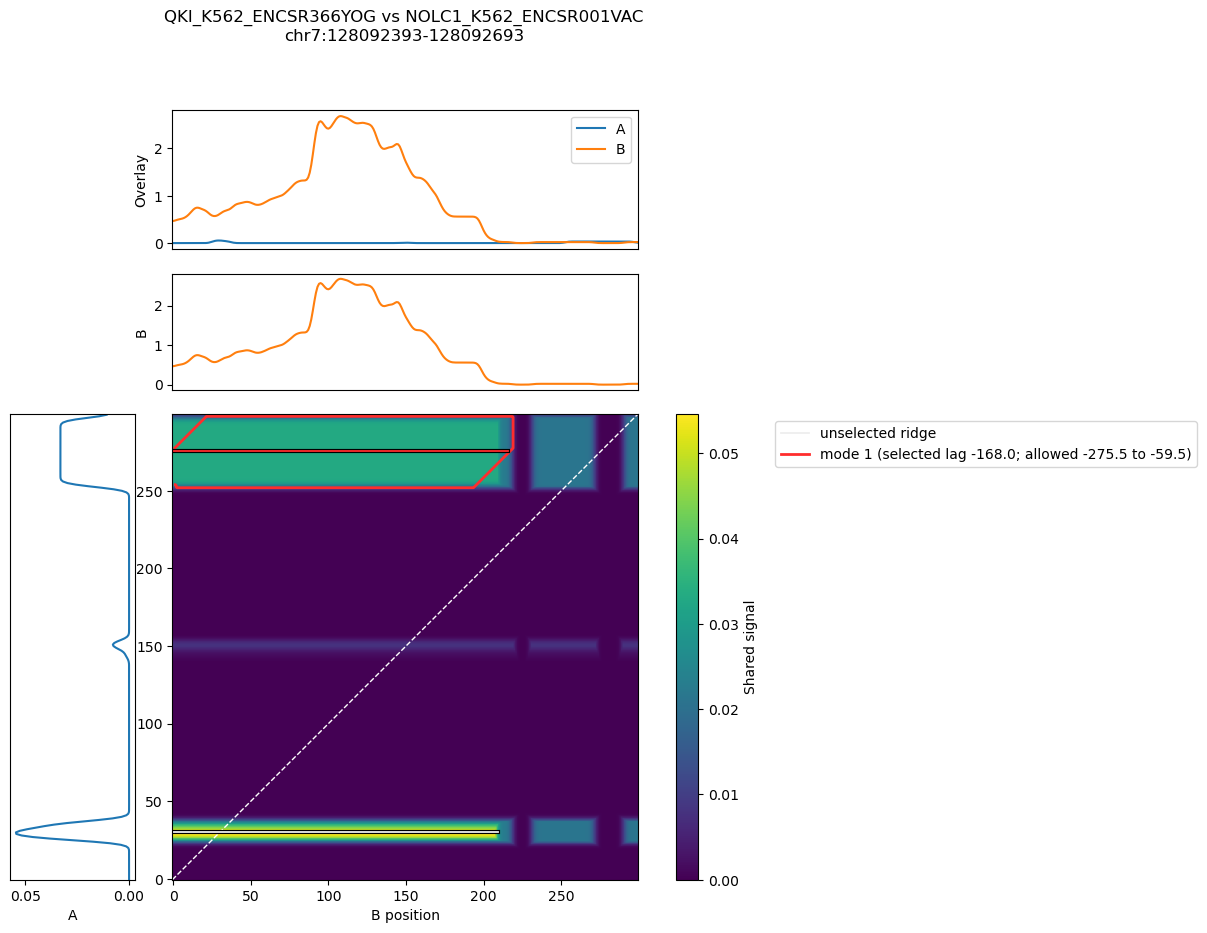

In [10]:
no_agreement = plot_category("no_agreement", island_parameters)

## Pure displacement

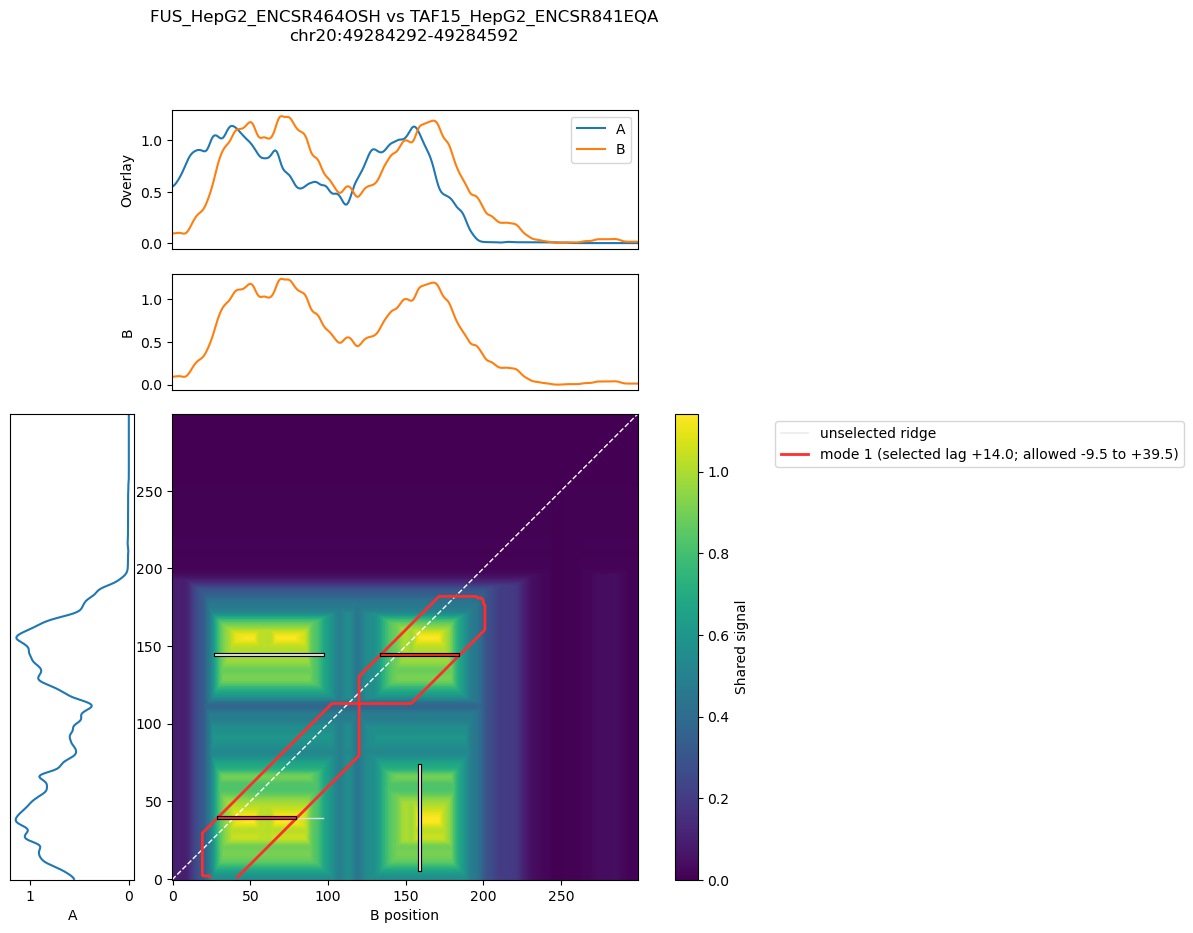

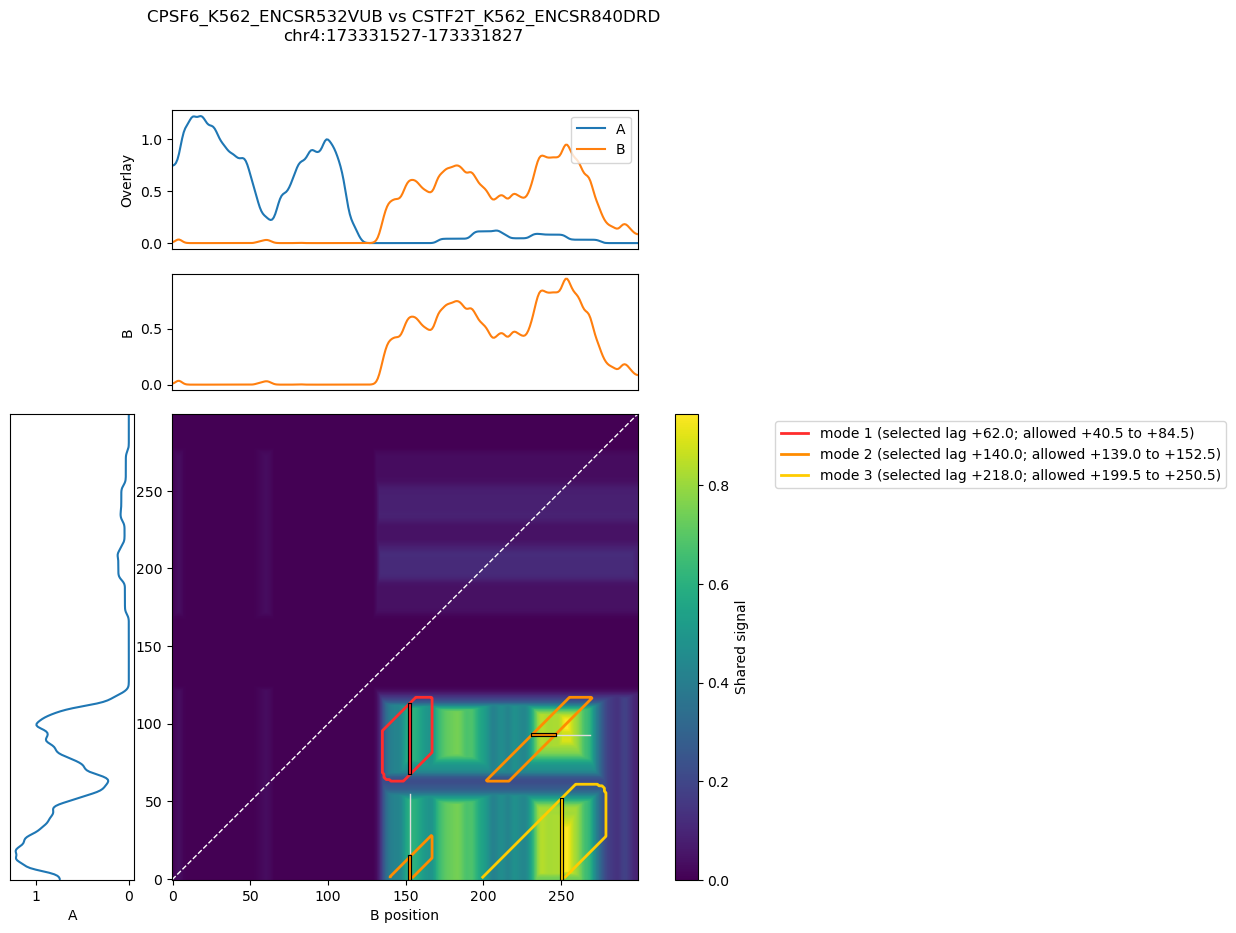

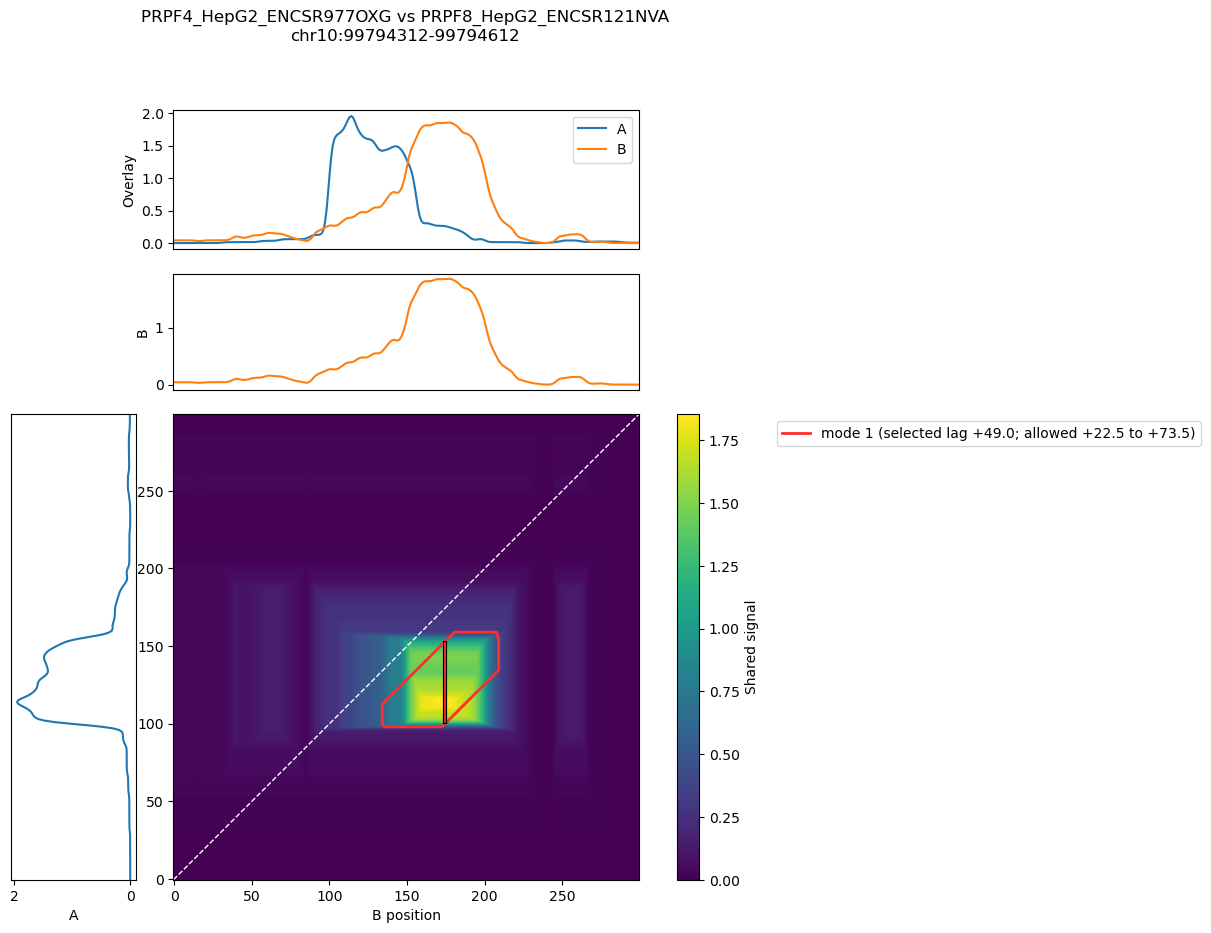

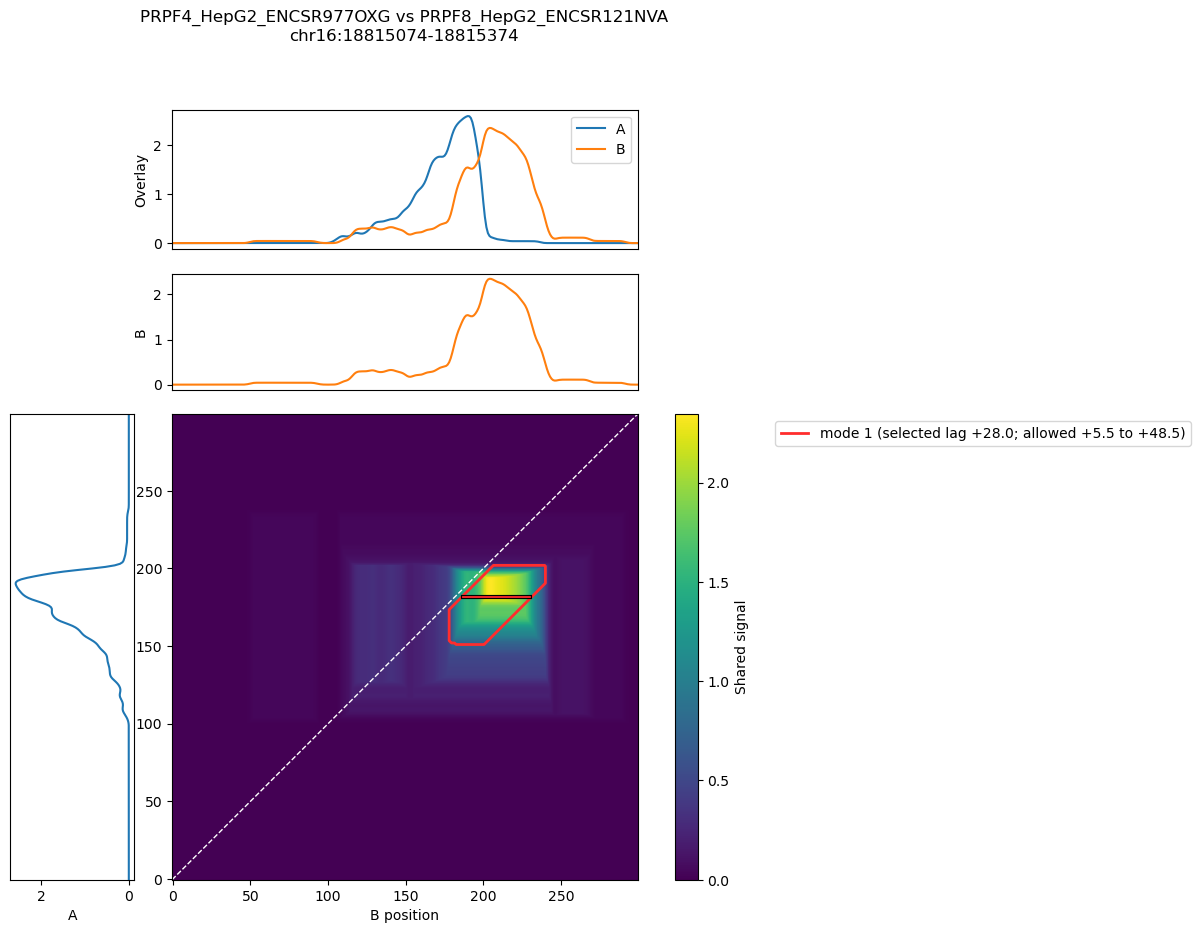

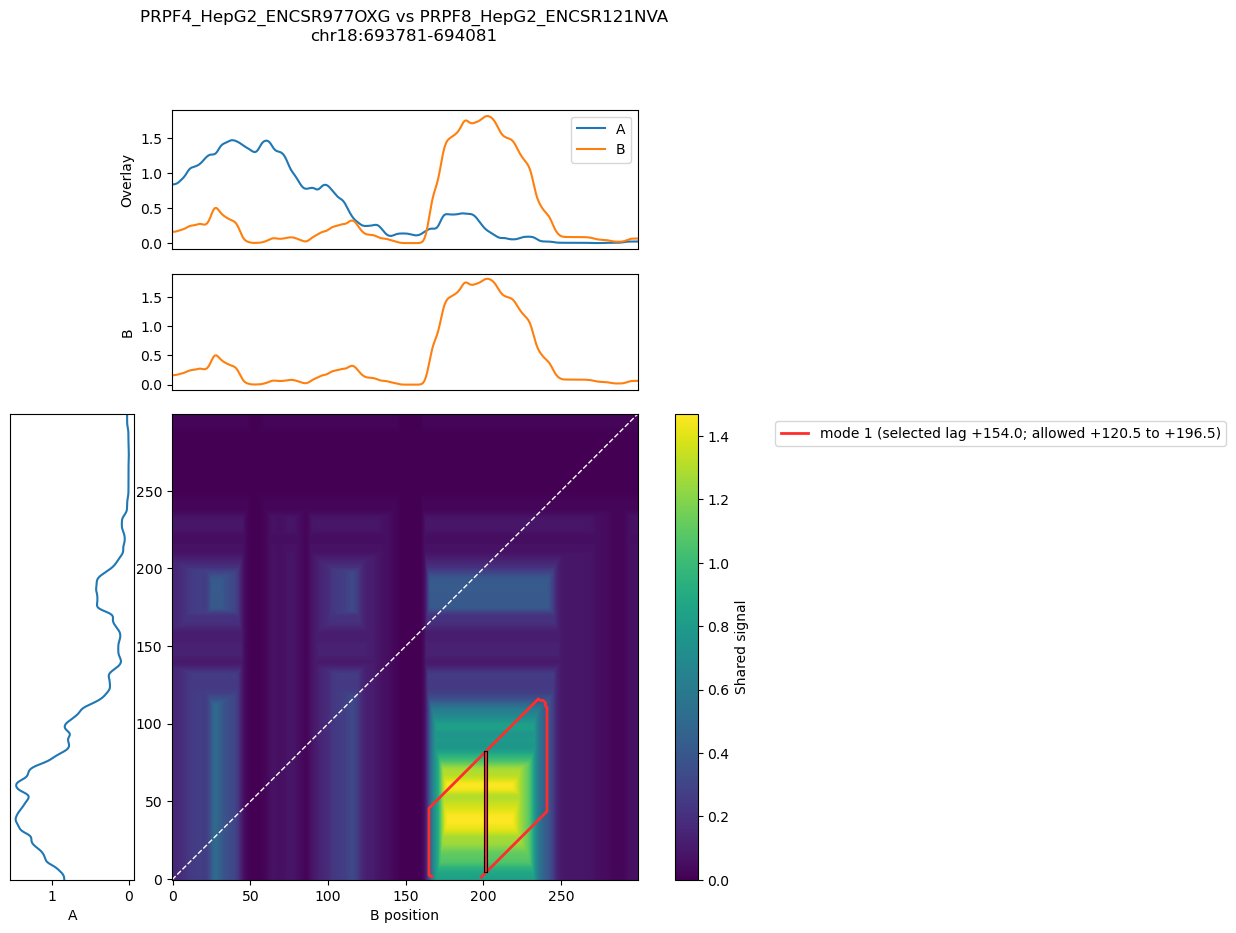

In [11]:
displacement = plot_category("pure_displacement", island_parameters)

## Shuffled offscreen

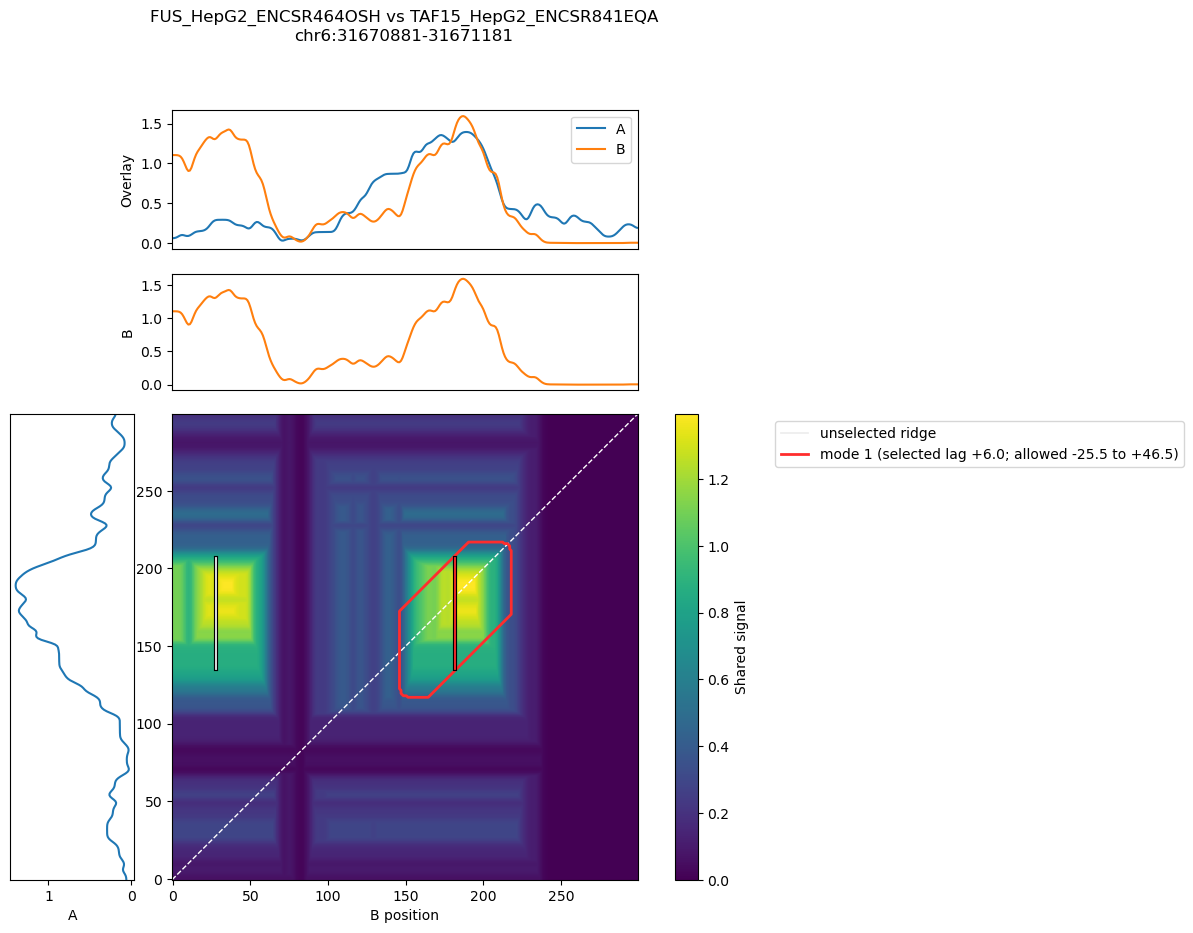

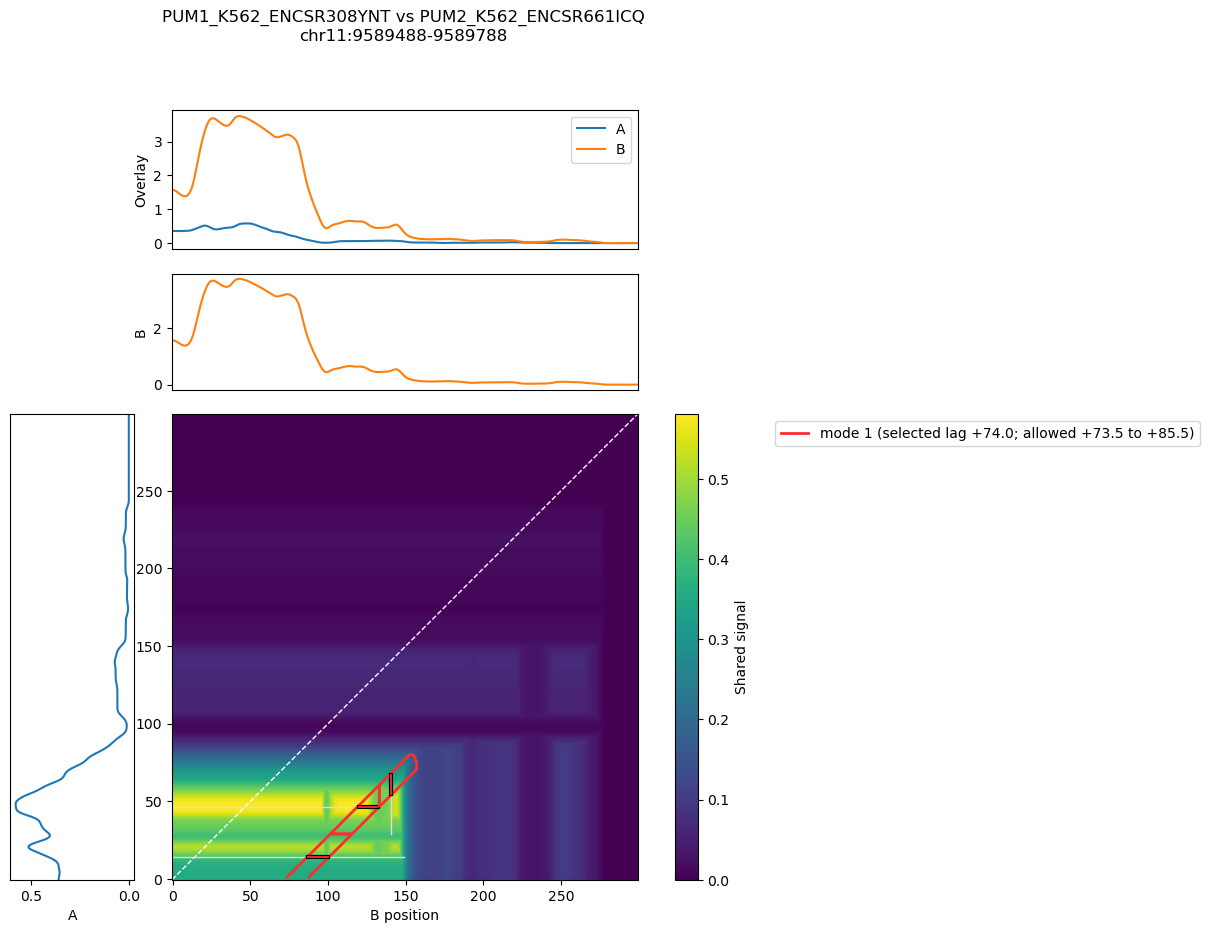

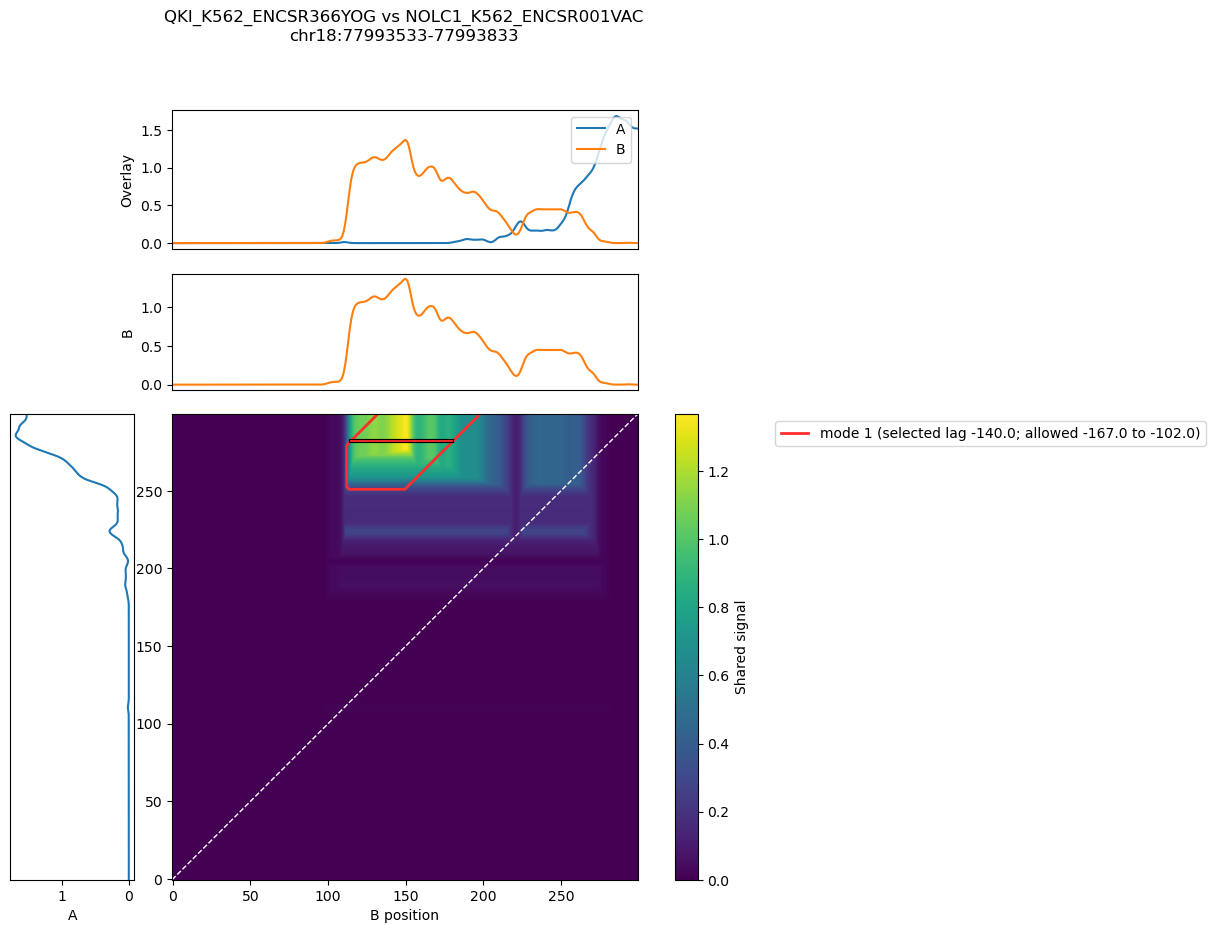

In [12]:
shuffled = plot_category("shuffled_off_screen", island_parameters)

## Noisy

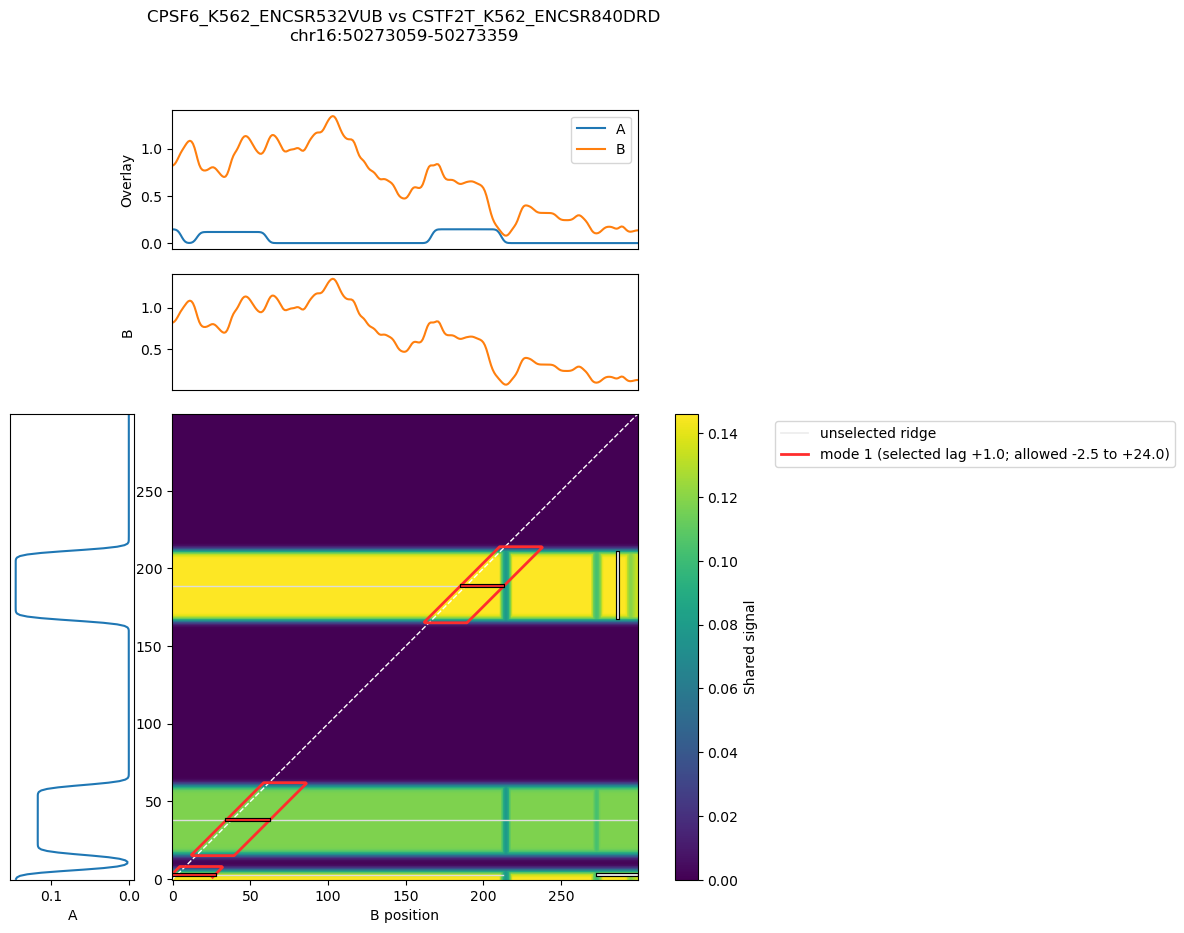

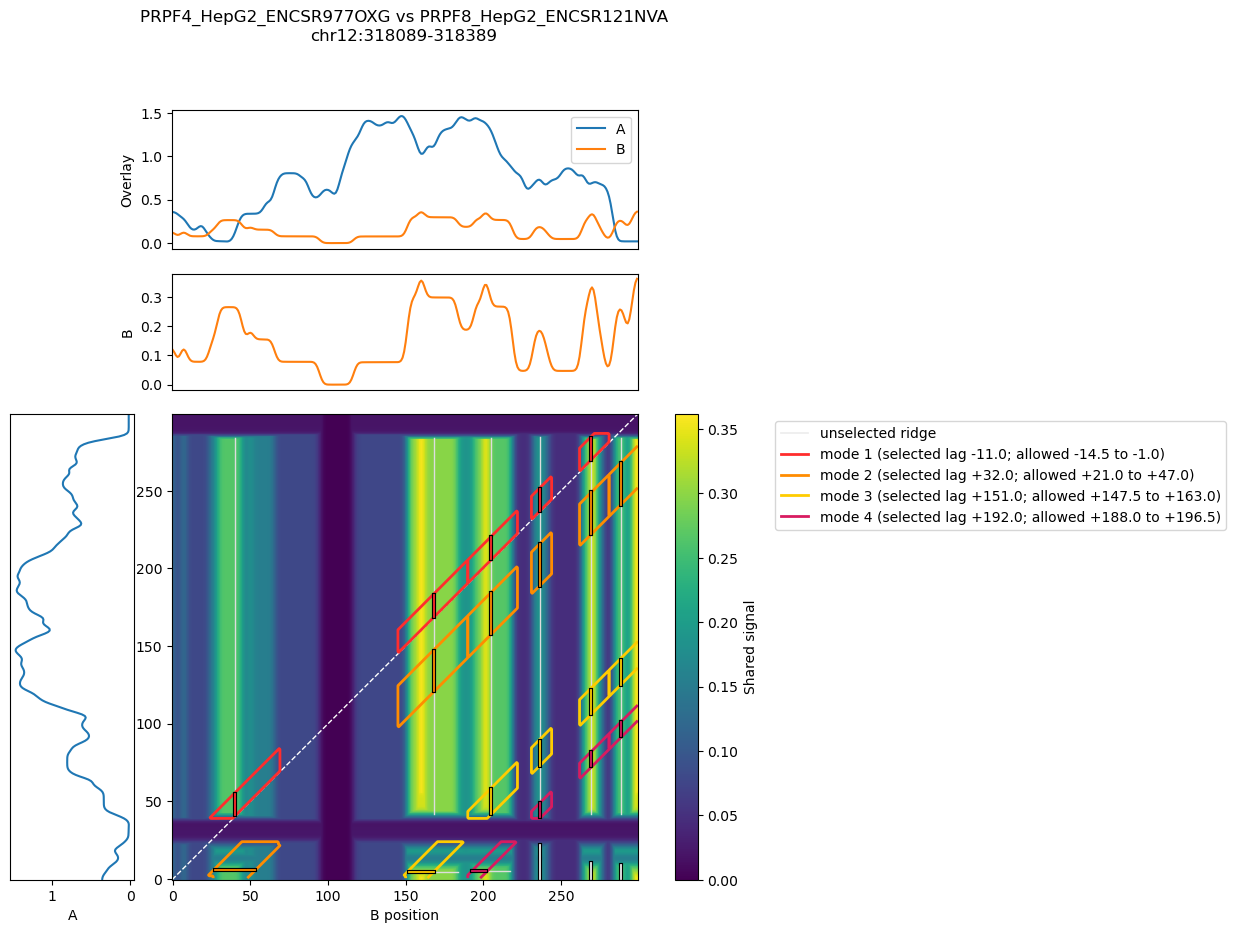

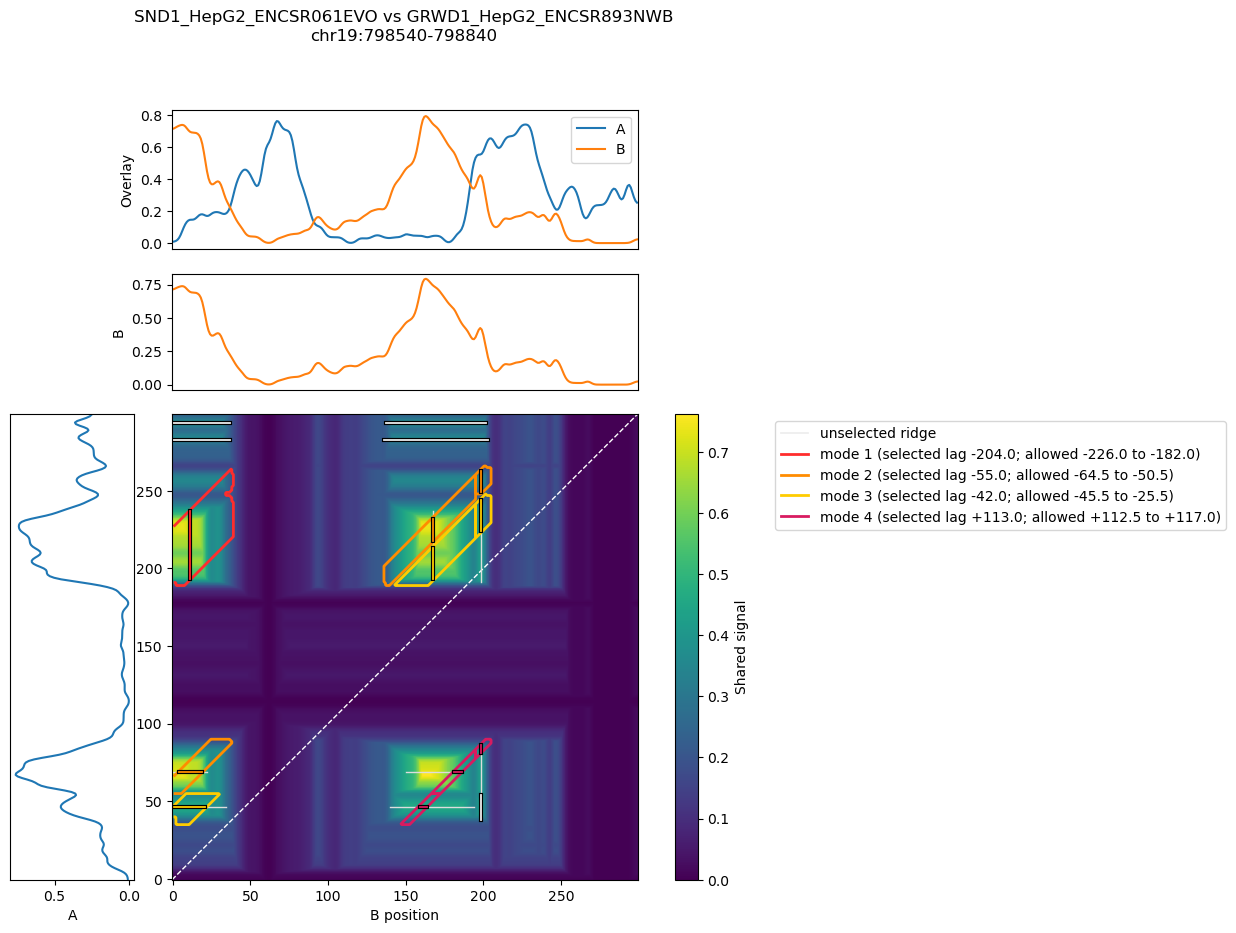

In [13]:
noisy = plot_category("noisy", island_parameters)

# Notes

- Of course it is an alignment problem. As a bioinformatician, how did I never think of that before? Did Pavel teach me nothing? I might actually have to look back at some old material for that, may be some useful notes, or stuff that can speed up the problem. 

- That first one I looked at brings up an interesting complex. Let's assume we select that main one as being the main one. In that case, we know for a FACT that there is only one other option for the second one. Like, there are those little bits at the ends that

- The noisy bits show off a meaningful problem with this definition of the best window, which is that it means that things close to the 0 line and far off the zero line are treated as equals. 